# RappiPlus | SQL Behavioral Analysis

## Project Objective

Analyze user behavior throughout the conversion funnel and evaluate customer retention using PostgreSQL.

### Business Questions

1. At which stages do users abandon the conversion funnel?
2. What percentage of users complete the purchase process?
3. How does user retention evolve after registration?
4. What opportunities can improve conversion and retention?

### Data Sources

The analysis uses three PostgreSQL tables:

- `public.events`: User interactions and navigation events.
- `public.users`: User registration information.
- `public.user_activity`: User activity after registration.

**Analysis period:** January–June 2025.

**Tools:** PostgreSQL, SQLAlchemy, Pandas, and Jupyter Notebook.

## 1. Database Connection

Establish a secure connection to PostgreSQL using environment variables.

Database credentials are stored in a local `.env` file and excluded from version control.

In [1]:
import pandas as pd
import os
from pathlib import Path
from dotenv import load_dotenv
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL
import matplotlib.pyplot as plt

# 1. Load database credentials
env_path = Path.cwd().parent / ".env"

if not env_path.exists():
    env_path = Path.cwd() / ".env"

load_dotenv(env_path, override=True)

# 2. Validate required credentials
required_vars = ["DB_USER", "DB_PASSWORD", "DB_HOST", "DB_NAME"]

missing_vars = [var for var in required_vars if not os.getenv(var)]

if missing_vars:
    raise ValueError(f"Missing environment variables: {missing_vars}")

# 3. Configure PostgreSQL connection
connection_url = URL.create(
    drivername="postgresql+psycopg2",
    username=os.getenv("DB_USER"),
    password=os.getenv("DB_PASSWORD"),
    host=os.getenv("DB_HOST"),
    port=int(os.getenv("DB_PORT", "5432")),
    database=os.getenv("DB_NAME")
)

# 4. Create database engine
engine = create_engine(
    connection_url,
    connect_args={
        "sslmode": "require",
        "connect_timeout": 10
    }
)

# 5. Test database connection
with engine.connect() as connection:
    result = connection.execute(text("SELECT 1"))
    print("Connection successful:", result.scalar())

Connection successful: 1


In [2]:
# Explore available database tables

query = """
SELECT
    table_schema,
    table_name
FROM information_schema.tables
WHERE table_schema NOT IN (
    'pg_catalog',
    'information_schema'
)
AND table_type = 'BASE TABLE'
ORDER BY table_schema, table_name;
"""

tables = pd.read_sql(query, engine)

print("Total tables:", len(tables))
display(tables)

Total tables: 128


,table_schema,table_name
0,online_store,costs
1,online_store,events
2,online_store,orders
3,online_store,profiles
4,online_store,sessions
...,...,...
123,tools_shop,order_x_item
124,tools_shop,orders
125,tools_shop,users
126,yammer,events


In [3]:
# Search for RappiPlus-related schemas and tables

relevant_tables = tables[
    tables['table_schema'].str.contains(
        'rappi|delivery|ecommerce|shop|store',
        case=False,
        na=False
    )
    |
    tables['table_name'].str.contains(
        'rappi|event|activity|session|cohort',
        case=False,
        na=False
    )
]

print("Potentially relevant tables:", len(relevant_tables))

display(relevant_tables.reset_index(drop=True))

Potentially relevant tables: 18


,table_schema,table_name
0,online_store,costs
1,online_store,events
2,online_store,orders
3,online_store,profiles
4,online_store,sessions
5,public,clientes_banco_eventos
6,public,eventos_ptbr
7,public,events
8,public,events_clean
9,public,user_activity


In [4]:
# Identify the default schema search path

query = """
SHOW search_path;
"""

pd.read_sql(query, engine)

,search_path
0,"""$user"", public"


In [5]:
# Explore candidate table structures

query = """
SELECT
    table_name,
    column_name,
    data_type
FROM information_schema.columns
WHERE table_schema = 'public'
  AND table_name IN (
      'events',
      'events_clean',
      'user_activity'
  )
ORDER BY table_name, ordinal_position;
"""

table_columns = pd.read_sql(query, engine)

display(table_columns)

,table_name,column_name,data_type
0,events,id_usuario,text
1,events,id_sesion,text
2,events,nombre_evento,text
3,events,timestamp_evento,text
4,events,pais,text
5,events,dispositivo,text
6,events,fuente_referencia,text
7,events,categoria_producto,text
8,events_clean,id_usuario,text
9,events_clean,id_sesion,text


In [6]:
# Find the users table in PostgreSQL

users_tables = tables[
    tables['table_name'] == 'users'
]

display(users_tables)

,table_schema,table_name
102,public,users
116,stackoverflow,users
125,tools_shop,users
127,yammer,users


In [7]:
# Inspect users table structure

query = """
SELECT
    column_name,
    data_type
FROM information_schema.columns
WHERE table_schema = 'public'
  AND table_name = 'users'
ORDER BY ordinal_position;
"""

users_columns = pd.read_sql(query, engine)

display(users_columns)

,column_name,data_type
0,id_usuario,text
1,fecha_registro,text
2,país,text
3,dispositivo,text
4,tipo_plan,text


In [8]:
# Validate SQL datasets

query = """
SELECT
    'events' AS table_name,
    COUNT(*) AS total_records,
    COUNT(DISTINCT id_usuario) AS unique_users,
    MIN(timestamp_evento::timestamp)::date AS first_date,
    MAX(timestamp_evento::timestamp)::date AS last_date
FROM public.events

UNION ALL

SELECT
    'users' AS table_name,
    COUNT(*) AS total_records,
    COUNT(DISTINCT id_usuario) AS unique_users,
    MIN(fecha_registro::date) AS first_date,
    MAX(fecha_registro::date) AS last_date
FROM public.users

UNION ALL

SELECT
    'user_activity' AS table_name,
    COUNT(*) AS total_records,
    COUNT(DISTINCT id_usuario) AS unique_users,
    MIN(fecha_actividad::date) AS first_date,
    MAX(fecha_actividad::date) AS last_date
FROM public.user_activity;
"""

sql_dataset_overview = pd.read_sql(query, engine)

display(sql_dataset_overview)

,table_name,total_records,unique_users,first_date,last_date
0,users,8000,8000,2025-01-01,2025-05-31
1,user_activity,32000,8000,2025-01-08,2025-06-28
2,events,120000,8000,2025-01-01,2025-06-30


## 2. Data Overview

The analysis is based on three behavioral datasets:

- **Users:** 8,000 registered users.
- **Events:** 120,000 user interactions.
- **User Activity:** 32,000 activity records.

All three datasets cover dates within the January–June 2025 analysis period.

The data structure and coverage were reviewed before beginning the SQL analysis.

## 3. Conversion Funnel Analysis

### Business Question

At which stages of the customer journey do users abandon the purchase process?

### Methodology

User interaction events will be analyzed using SQL to identify the main conversion stages, calculate user conversion rates, and detect potential bottlenecks in the purchase funnel.

In [9]:
# Identify available funnel events

query = """
SELECT
    nombre_evento,
    COUNT(*) AS total_events,
    COUNT(DISTINCT id_usuario) AS unique_users
FROM public.events
GROUP BY nombre_evento
ORDER BY total_events DESC;
"""

event_summary = pd.read_sql(query, engine)

display(event_summary)

,nombre_evento,total_events,unique_users
0,first_visit,29957,7796
1,add_to_cart,24157,7634
2,select_item,23887,7582
3,begin_checkout,17971,7208
4,add_payment_info,12018,6250
5,purchase,12010,6240


In [10]:
# Build a sequential conversion funnel

query = """
WITH ordered_events AS (
    SELECT
        id_usuario,
        nombre_evento,
        timestamp_evento::timestamp AS event_time
    FROM public.events
),

first_visits AS (
    SELECT
        id_usuario,
        MIN(event_time) AS first_visit_time
    FROM ordered_events
    WHERE nombre_evento = 'first_visit'
    GROUP BY id_usuario
),

selected_items AS (
    SELECT
        e.id_usuario,
        MIN(e.event_time) AS select_time
    FROM ordered_events e
    JOIN first_visits f
        ON e.id_usuario = f.id_usuario
    WHERE e.nombre_evento = 'select_item'
      AND e.event_time >= f.first_visit_time
    GROUP BY e.id_usuario
),

added_to_cart AS (
    SELECT
        e.id_usuario,
        MIN(e.event_time) AS cart_time
    FROM ordered_events e
    JOIN selected_items s
        ON e.id_usuario = s.id_usuario
    WHERE e.nombre_evento = 'add_to_cart'
      AND e.event_time >= s.select_time
    GROUP BY e.id_usuario
),

started_checkout AS (
    SELECT
        e.id_usuario,
        MIN(e.event_time) AS checkout_time
    FROM ordered_events e
    JOIN added_to_cart c
        ON e.id_usuario = c.id_usuario
    WHERE e.nombre_evento = 'begin_checkout'
      AND e.event_time >= c.cart_time
    GROUP BY e.id_usuario
),

added_payment AS (
    SELECT
        e.id_usuario,
        MIN(e.event_time) AS payment_time
    FROM ordered_events e
    JOIN started_checkout c
        ON e.id_usuario = c.id_usuario
    WHERE e.nombre_evento = 'add_payment_info'
      AND e.event_time >= c.checkout_time
    GROUP BY e.id_usuario
),

purchased AS (
    SELECT
        e.id_usuario,
        MIN(e.event_time) AS purchase_time
    FROM ordered_events e
    JOIN added_payment p
        ON e.id_usuario = p.id_usuario
    WHERE e.nombre_evento = 'purchase'
      AND e.event_time >= p.payment_time
    GROUP BY e.id_usuario
)

SELECT 1 AS stage_order, 'first_visit' AS stage, COUNT(*) AS users
FROM first_visits

UNION ALL
SELECT 2, 'select_item', COUNT(*)
FROM selected_items

UNION ALL
SELECT 3, 'add_to_cart', COUNT(*)
FROM added_to_cart

UNION ALL
SELECT 4, 'begin_checkout', COUNT(*)
FROM started_checkout

UNION ALL
SELECT 5, 'add_payment_info', COUNT(*)
FROM added_payment

UNION ALL
SELECT 6, 'purchase', COUNT(*)
FROM purchased

ORDER BY stage_order;
"""

funnel = pd.read_sql(query, engine)

display(funnel)

,stage_order,stage,users
0,1,first_visit,7796
1,2,select_item,6728
2,3,add_to_cart,4983
3,4,begin_checkout,2663
4,5,add_payment_info,919
5,6,purchase,258


In [11]:
# Calculate funnel conversion and drop-off rates

funnel['step_conversion_pct'] = (
    funnel['users']
    / funnel['users'].shift(1)
    * 100
)

funnel['dropoff_pct'] = (
    100 - funnel['step_conversion_pct']
)

funnel['overall_conversion_pct'] = (
    funnel['users']
    / funnel['users'].iloc[0]
    * 100
)

# The first stage is the funnel baseline
funnel.loc[0, 'step_conversion_pct'] = 100
funnel.loc[0, 'dropoff_pct'] = 0

display(funnel.round(2))

,stage_order,stage,users,step_conversion_pct,dropoff_pct,overall_conversion_pct
0,1,first_visit,7796,100.00,0.00,100.00
1,2,select_item,6728,86.30,13.70,86.30
2,3,add_to_cart,4983,74.06,25.94,63.92
3,4,begin_checkout,2663,53.44,46.56,34.16
4,5,add_payment_info,919,34.51,65.49,11.79
5,6,purchase,258,28.07,71.93,3.31


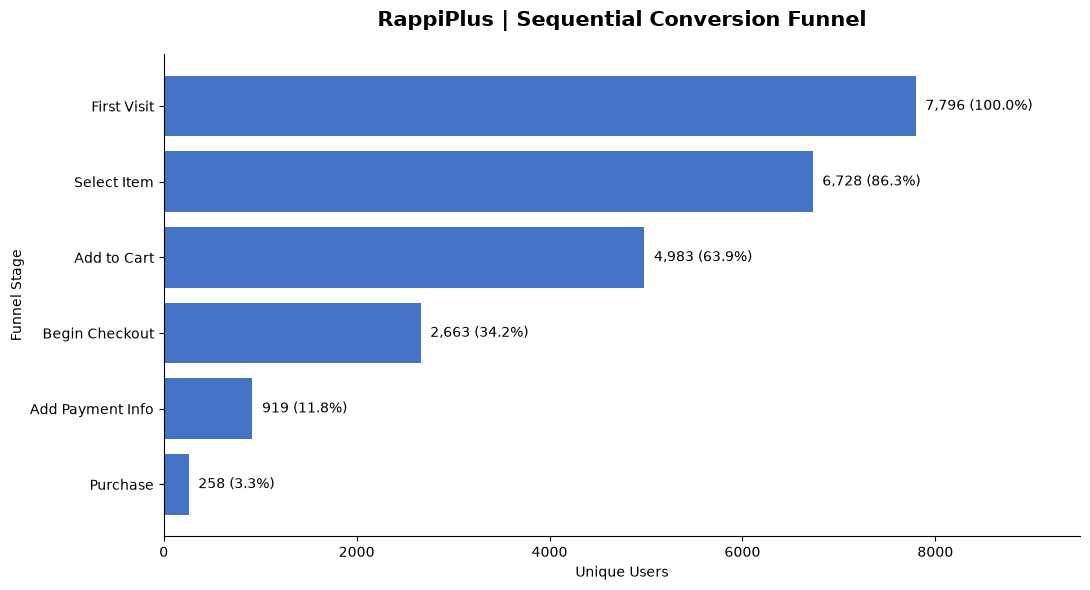

In [12]:
# Visualize the sequential conversion funnel

fig, ax = plt.subplots(figsize=(11, 6))

stages = [
    'First Visit',
    'Select Item',
    'Add to Cart',
    'Begin Checkout',
    'Add Payment Info',
    'Purchase'
]

users = funnel['users'].values

bars = ax.barh(
    stages,
    users,
    color='#4472C4'
)

# Display user counts and overall conversion rates
for i, bar in enumerate(bars):
    ax.text(
        bar.get_width() + 100,
        bar.get_y() + bar.get_height() / 2,
        f"{users[i]:,} ({funnel['overall_conversion_pct'].iloc[i]:.1f}%)",
        va='center',
        fontsize=10
    )

ax.invert_yaxis()

ax.set_title(
    'RappiPlus | Sequential Conversion Funnel',
    fontsize=15,
    fontweight='bold',
    pad=20
)

ax.set_xlabel('Unique Users')
ax.set_ylabel('Funnel Stage')

ax.set_xlim(0, 9500)

ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()

In [13]:
# Check user overlap between SQL events and business orders

query = """
SELECT DISTINCT id_usuario
FROM public.events
WHERE id_usuario IS NOT NULL;
"""

sql_users = pd.read_sql(query, engine)

business_orders = pd.read_csv(
    "../data/processed/rappiplus_orders_clean.csv"
)

business_users = set(
    business_orders["id_usuario"].dropna().astype(str)
)

event_users = set(
    sql_users["id_usuario"].dropna().astype(str)
)

common_users = business_users & event_users

print("Business analysis users:", len(business_users))
print("SQL event users:", len(event_users))
print("Users present in both:", len(common_users))

Business analysis users: 7642
SQL event users: 8000
Users present in both: 7642


## 4. Cohort Retention Analysis

### Business Question

How does user retention evolve after registration, and which registration cohorts demonstrate stronger engagement?

### Methodology

Users will be grouped into monthly registration cohorts using `public.users`.

Their subsequent activity will be evaluated using `public.user_activity` to calculate retention rates at specific intervals after registration.

Retention will be defined as the percentage of users in each cohort who were active at the evaluated interval.

In [14]:
# Validate user identifier consistency across retention datasets

query = """
WITH registered_users AS (
    SELECT DISTINCT id_usuario
    FROM public.users
    WHERE id_usuario IS NOT NULL
),

active_users AS (
    SELECT DISTINCT id_usuario
    FROM public.user_activity
    WHERE id_usuario IS NOT NULL
),

event_users AS (
    SELECT DISTINCT id_usuario
    FROM public.events
    WHERE id_usuario IS NOT NULL
)

SELECT
    (SELECT COUNT(*) FROM registered_users) AS registered_users,
    (SELECT COUNT(*) FROM active_users) AS activity_users,
    (SELECT COUNT(*) FROM event_users) AS event_users,

    (
        SELECT COUNT(*)
        FROM registered_users u
        INNER JOIN active_users a
            ON u.id_usuario = a.id_usuario
    ) AS users_matching_activity,

    (
        SELECT COUNT(*)
        FROM registered_users u
        INNER JOIN event_users e
            ON u.id_usuario = e.id_usuario
    ) AS users_matching_events;
"""

user_consistency = pd.read_sql(query, engine)

display(user_consistency)

,registered_users,activity_users,event_users,users_matching_activity,users_matching_events
0,8000,8000,8000,8000,8000


In [15]:
# Explore available retention intervals

query = """
SELECT
    dias_despues_registro,
    COUNT(*) AS total_records,
    COUNT(DISTINCT id_usuario) AS evaluated_users,
    SUM(CASE WHEN activo = 1 THEN 1 ELSE 0 END) AS active_users
FROM public.user_activity
GROUP BY dias_despues_registro
ORDER BY dias_despues_registro;
"""

retention_intervals = pd.read_sql(query, engine)

display(retention_intervals)

,dias_despues_registro,total_records,evaluated_users,active_users
0,7,8000,8000,3360
1,14,8000,8000,3355
2,21,8000,8000,3350
3,28,8000,8000,3250


In [16]:
# Calculate retention by registration cohort

query = """
WITH user_cohorts AS (
    SELECT
        id_usuario,
        DATE_TRUNC('month', fecha_registro::date)::date AS cohort_month
    FROM public.users
),

cohort_activity AS (
    SELECT
        u.cohort_month,
        a.dias_despues_registro,
        COUNT(DISTINCT a.id_usuario) AS evaluated_users,
        COUNT(DISTINCT CASE
            WHEN a.activo = 1 THEN a.id_usuario
        END) AS active_users
    FROM user_cohorts u
    INNER JOIN public.user_activity a
        ON u.id_usuario = a.id_usuario
    GROUP BY
        u.cohort_month,
        a.dias_despues_registro
)

SELECT
    cohort_month,
    dias_despues_registro,
    evaluated_users,
    active_users,
    ROUND(
        active_users * 100.0 / NULLIF(evaluated_users, 0),
        2
    ) AS retention_pct
FROM cohort_activity
ORDER BY
    cohort_month,
    dias_despues_registro;
"""

cohort_retention = pd.read_sql(query, engine)

display(cohort_retention)

,cohort_month,dias_despues_registro,evaluated_users,active_users,retention_pct
0,2025-01-01,7,1627,697,42.84
1,2025-01-01,14,1627,668,41.06
2,2025-01-01,21,1627,656,40.32
3,2025-01-01,28,1627,671,41.24
4,2025-02-01,7,1444,611,42.31
5,2025-02-01,14,1444,609,42.17
6,2025-02-01,21,1444,635,43.98
7,2025-02-01,28,1444,575,39.82
8,2025-03-01,7,1636,677,41.38
9,2025-03-01,14,1636,705,43.09


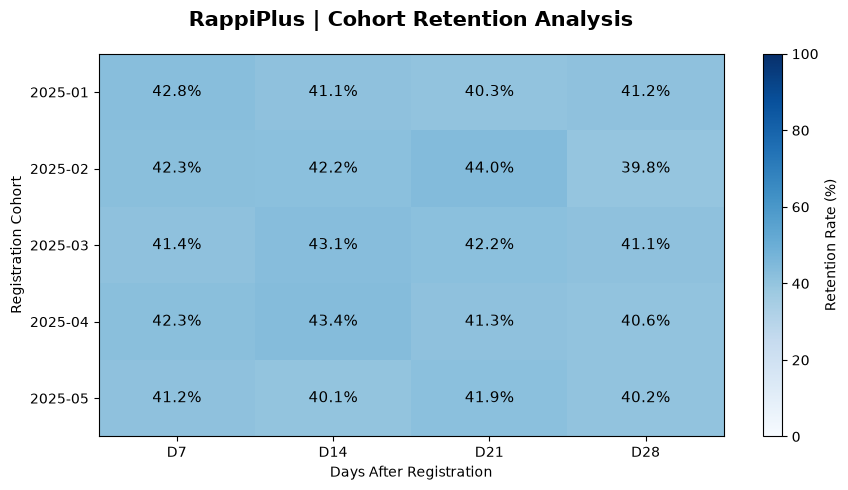

In [17]:
# Create cohort retention matrix

retention_matrix = cohort_retention.pivot(
    index='cohort_month',
    columns='dias_despues_registro',
    values='retention_pct'
)

# Format cohort labels
retention_matrix.index = pd.to_datetime(
    retention_matrix.index
).strftime('%Y-%m')

# Rename retention intervals
retention_matrix.columns = [
    f'D{day}' for day in retention_matrix.columns
]

# Visualize cohort retention
fig, ax = plt.subplots(figsize=(9, 5))

heatmap = ax.imshow(
    retention_matrix.values,
    cmap='Blues',
    aspect='auto',
    vmin=0,
    vmax=100
)

ax.set_xticks(range(len(retention_matrix.columns)))
ax.set_xticklabels(retention_matrix.columns)

ax.set_yticks(range(len(retention_matrix.index)))
ax.set_yticklabels(retention_matrix.index)

# Display retention percentages
for i in range(len(retention_matrix.index)):
    for j in range(len(retention_matrix.columns)):
        value = retention_matrix.iloc[i, j]

        ax.text(
            j, i,
            f'{value:.1f}%',
            ha='center',
            va='center',
            color='white' if value >= 50 else 'black',
            fontsize=11
        )

ax.set_title(
    'RappiPlus | Cohort Retention Analysis',
    fontsize=15,
    fontweight='bold',
    pad=20
)

ax.set_xlabel('Days After Registration')
ax.set_ylabel('Registration Cohort')

colorbar = fig.colorbar(heatmap, ax=ax)
colorbar.set_label('Retention Rate (%)')

plt.tight_layout()
plt.show()

### Key Findings: Cohort Retention

The cohort analysis evaluated user activity at 7, 14, 21, and 28 days after registration across five monthly cohorts from January to May 2025.

**Key Results**

* Retention rates ranged from **39.82% to 43.98%** across cohorts and evaluation intervals.
* The February cohort recorded the highest individual retention rate at **D21 (43.98%)**.
* The January cohort showed the highest D28 retention rate (**41.24%**).
* Retention patterns remained relatively stable across registration cohorts, with no consistent improvement over time.

### Business Implications

The results suggest relatively consistent user engagement patterns across registration cohorts.

However, approximately 59% of registered users were inactive at the D28 evaluation point.

This highlights an opportunity to investigate factors influencing continued platform engagement.

### Recommendations

* Analyze retention differences by country, acquisition channel, and device.
* Investigate engagement patterns among users who become inactive.
* Evaluate targeted onboarding and re-engagement initiatives to improve user activity after registration.

### Analytical Limitations

Retention is measured as activity on specific days after registration (D7, D14, D21, and D28), rather than continuous activity throughout the observation period.

Therefore, these metrics should not be interpreted as cumulative retention or permanent customer abandonment.

The analysis measures platform activity, not repeat purchases.


## 5. Executive Summary

### Business Performance Insights

This analysis examined RappiPlus user behavior using PostgreSQL, focusing on sequential purchase funnel progression and user retention after registration.

### Key Findings

**1. Conversion Funnel**

* The analysis identified 7,796 users with a recorded first-visit event.
* Only 258 users (3.31%) completed all six funnel stages in the required sequence.
* The largest relative drop-off occurred between Add Payment Info and Purchase (71.93%).
* The largest absolute decrease occurred between Add to Cart and Begin Checkout (2,320 users).

**2. Cohort Retention**

* Retention rates ranged from 39.82% to 43.98% across monthly registration cohorts and evaluation intervals.
* The February cohort recorded the highest individual retention rate at D21 (43.98%).
* D28 retention remained near 40% across all five registration cohorts.
* No consistent improvement in retention was observed across registration months.

### Business Recommendations

**1. Investigate Checkout Friction**

Examine user behavior during checkout and payment to identify potential obstacles and verify event-tracking consistency.

**2. Improve User Engagement**

Evaluate onboarding and re-engagement initiatives to encourage activity after registration.

**3. Strengthen Behavioral Measurement**

Monitor user progression and retention by relevant segments, including device, country, and acquisition channel.

### Analytical Limitations

The conversion funnel measures completion of a strict event sequence at the user level, potentially across different sessions and dates.

Therefore, the 3.31% sequential funnel completion rate should not be interpreted as the platform's overall purchase conversion rate.

Cohort retention measures activity on specific days after registration, rather than continuous activity or repeat purchases.

Although user identifiers overlap across the commercial and behavioral datasets, recorded purchase events and completed orders represent different measurement criteria.

### Conclusion

RappiPlus demonstrates measurable user engagement across registration cohorts, but the sequential funnel reveals substantial reductions in progression through checkout-related stages.

These findings highlight opportunities to improve behavioral measurement, investigate purchase-process friction, and strengthen user engagement.

Further analysis is recommended before attributing observed behavior to specific business or product issues.
